# 04 · Personalised few-shot fine-tuning

A player's handwriting is fairly consistent: the same 7 with a crossbar, the same open 4. If
the game collected a few labelled samples from *this* player (e.g. a 30-second "write 0–9"
calibration, or answers the game was sure about), could it adapt the model on the device?

**Setup**
- Base models from notebook 03: `cnn_aug_pad` (strong) and `cnn_mnist` (weak, MNIST only).
- Synthetic writers from the template generator (never used to train a base model), 30
  samples per digit each. For each writer: *k* support samples per digit (k = 1, 2, 5, 10, 20)
  for adaptation, the last 10 per digit (100 samples) for testing.
- Two kinds of writers:
  - `consistent` (`pad_tmpl_writers`, notebook 01): every sample of a digit uses the writer's
    one style with small variation;
  - `variable`: twice the sample-to-sample variation, and 20% of samples use another style of
    the digit. Closer to a real person; a first run with only consistent writers showed that
    they are far too easy (≈100% after one sample per digit).
- Writers 0–9 of the `variable` set pick hyper-parameters; writers 10–39 report results.

**Methods** (the convolutional feature extractor stays frozen, so on a device only a tiny
part of the model is trained or stored):
1. `head`: fine-tune the last two dense layers (`embedding` + `classifier`, 4,810 parameters)
   with Adam from the base weights, plus an L2 pull towards the base weights so a handful of
   samples cannot wreck the model.
2. `head+aug`: same, but each support image also appears as 4 randomly rotated/zoomed/shifted copies.
3. `proto`: no training — average the 64-d embeddings of the support samples per digit
   (prototypes) and add a cosine-similarity bonus to the base model's log-probabilities.

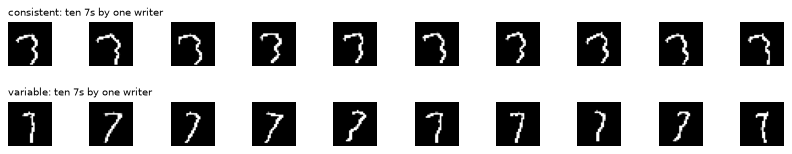

In [1]:
import os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
import keras

import datasets
import evaluate as ev

plt.rcParams['figure.dpi'] = 80
keras.utils.set_random_seed(0)
writers = {
    'consistent': datasets.template_set(40, 30, 'pad_tmpl_writers', seed=20),
    'variable': datasets.template_set(40, 30, 'pad_tmpl_writers_var', seed=21, noise=2.0, switch=0.2),
}
bases = {n: keras.models.load_model(datasets.CACHE / 'models' / f'{n}.keras') for n in ['cnn_aug_pad', 'cnn_mnist']}

fig, ax = plt.subplots(2, 10, figsize=(10, 2.2))
for r, (name, (x, y, w)) in enumerate(writers.items()):
    idx = np.nonzero((w == 3) & (y == 7))[0][:10]          # ten 7s of one writer
    for a, i in zip(ax[r], idx):
        a.imshow(x[i], cmap='gray'); a.axis('off')
    ax[r, 0].set_title(f'{name}: ten 7s by one writer', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

In [2]:
def split_model(m):
    """Frozen feature extractor (conv stack -> global pooling) and the head's weights."""
    gap = next(l for l in m.layers if isinstance(l, keras.layers.GlobalAveragePooling2D))
    feat = keras.Model(m.inputs, gap.output)
    emb, clf = m.get_layer('embedding'), m.get_layer('classifier')
    return (lambda x: feat(x[..., None], training=False).numpy()), feat, [w.numpy() for w in emb.weights + clf.weights]

def head_forward(f, W, emb_only=False):
    e = tf.nn.relu(f @ W[0] + W[1])
    return e if emb_only else tf.nn.softmax(e @ W[2] + W[3])

@tf.function(reduce_retracing=True)
def _adam(f, y, W0, steps, lr, l2):
    """Plain Adam on the head (the same loop the browser would run, see export/bench.html)."""
    W, m, v = list(W0), [tf.zeros_like(w) for w in W0], [tf.zeros_like(w) for w in W0]
    for t in tf.range(1, steps + 1):
        with tf.GradientTape() as tape:
            tape.watch(W)
            p = head_forward(f, W)
            loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(y, p))
            loss += l2 * tf.add_n([tf.reduce_sum((w - w0) ** 2) for w, w0 in zip(W, W0)])
        g = tape.gradient(loss, W)
        tt = tf.cast(t, tf.float32)
        m = [0.9 * a + 0.1 * b for a, b in zip(m, g)]
        v = [0.999 * a + 0.001 * b * b for a, b in zip(v, g)]
        W = [w - lr * (a / (1 - 0.9 ** tt)) / (tf.sqrt(b / (1 - 0.999 ** tt)) + 1e-7) for w, a, b in zip(W, m, v)]
    return W

def finetune_head(f_s, y_s, W0, steps=60, lr=3e-3, l2=1e-2):
    W = _adam(tf.constant(f_s), tf.constant(y_s), [tf.constant(w) for w in W0],
              tf.constant(steps), tf.constant(lr), tf.constant(l2))
    return [w.numpy() for w in W]

def proto_predict(f_s, y_s, f_q, W0, tau=10.0):
    e_s = head_forward(f_s, W0, emb_only=True).numpy()
    e_q = head_forward(f_q, W0, emb_only=True).numpy()
    norm = lambda e: e / (np.linalg.norm(e, axis=1, keepdims=True) + 1e-8)
    protos = norm(np.stack([e_s[y_s == d].mean(0) for d in range(10)]))
    return np.log(head_forward(f_q, W0).numpy() + 1e-9) + tau * (norm(e_q) @ protos.T)

aug = keras.Sequential([keras.layers.RandomRotation(0.04), keras.layers.RandomZoom(0.1),
                        keras.layers.RandomTranslation(0.06, 0.06)])

def augmented(x, copies=4):
    return np.concatenate([x] + [aug(x[..., None], training=True).numpy()[..., 0] for _ in range(copies)])

In [3]:
def run_writer(feat, W0, data, wid, k, method, hp):
    x_all, y_all, w_all = data
    m = w_all == wid
    x, y = x_all[m], y_all[m]
    order = np.arange(len(y)) % 30                      # sample index within its digit
    f_q, y_q = feat(x[order >= 20]), y[order >= 20]
    if k == 0:
        return (head_forward(f_q, W0).numpy().argmax(1) == y_q).mean()
    xs, ys = x[order < k], y[order < k]
    if method == 'head+aug':
        xs, ys = augmented(xs), np.tile(ys, 5)
    f_s = feat(xs)
    if method == 'proto':
        pred = proto_predict(f_s, ys, f_q, W0, hp['tau']).argmax(1)
    else:
        pred = head_forward(f_q, finetune_head(f_s, ys, W0, **hp)).numpy().argmax(1)
    return (pred == y_q).mean()

## Hyper-parameters on the dev writers (variable set, writers 0–9, k = 5)

In [4]:
feat, _, W0 = split_model(bases['cnn_aug_pad'])
grid = {'head': [dict(steps=s, lr=3e-3, l2=l) for s in (30, 100) for l in (1e-3, 1e-2)],
        'proto': [dict(tau=t) for t in (3.0, 10.0, 30.0)]}
best_hp = {}
for method, options in grid.items():
    scores = [np.mean([run_writer(feat, W0, writers['variable'], w, 5, method, hp) for w in range(10)])
              for hp in options]
    best_hp[method] = options[int(np.argmax(scores))]
    print(method, [f'{s:.3f}' for s in scores], '-> best', best_hp[method])
best_hp['head+aug'] = best_hp['head']

head ['0.965', '0.963', '0.969', '0.963'] -> best {'steps': 100, 'lr': 0.003, 'l2': 0.001}


proto ['0.904', '0.909', '0.923'] -> best {'tau': 30.0}


## Accuracy vs. number of samples per digit (test writers 10–39)

In [5]:
KS = [0, 1, 2, 5, 10, 20]
METHODS = ['head', 'head+aug', 'proto']
RUNS = [('cnn_aug_pad', 'consistent'), ('cnn_aug_pad', 'variable'), ('cnn_mnist', 'variable')]
curves = {}
t0 = time.time()
for base_name, wset in RUNS:
    feat, _, W0 = split_model(bases[base_name])
    for method in METHODS:
        curves[(base_name, wset, method)] = np.array(
            [[run_writer(feat, W0, writers[wset], w, k, method, best_hp[method]) for k in KS] for w in range(10, 40)])
print(f'{(time.time() - t0) / 60:.1f} min')
for (b, wset, method), acc in curves.items():
    print(f'{b:12s} {wset:10s} {method:9s} ' + '  '.join(f'k={k}: {a:.1%}' for k, a in zip(KS, acc.mean(0))))

14.6 min
cnn_aug_pad  consistent head      k=0: 94.8%  k=1: 99.8%  k=2: 100.0%  k=5: 100.0%  k=10: 100.0%  k=20: 100.0%
cnn_aug_pad  consistent head+aug  k=0: 94.8%  k=1: 99.8%  k=2: 99.9%  k=5: 100.0%  k=10: 100.0%  k=20: 99.9%
cnn_aug_pad  consistent proto     k=0: 94.8%  k=1: 98.2%  k=2: 98.3%  k=5: 98.5%  k=10: 98.4%  k=20: 98.4%
cnn_aug_pad  variable   head      k=0: 90.8%  k=1: 95.7%  k=2: 96.6%  k=5: 97.2%  k=10: 97.6%  k=20: 98.2%
cnn_aug_pad  variable   head+aug  k=0: 90.8%  k=1: 95.5%  k=2: 96.7%  k=5: 97.0%  k=10: 97.7%  k=20: 97.9%
cnn_aug_pad  variable   proto     k=0: 90.8%  k=1: 93.6%  k=2: 94.4%  k=5: 94.6%  k=10: 94.4%  k=20: 94.5%
cnn_mnist    variable   head      k=0: 86.9%  k=1: 93.0%  k=2: 94.8%  k=5: 96.2%  k=10: 97.1%  k=20: 97.6%
cnn_mnist    variable   head+aug  k=0: 86.9%  k=1: 92.6%  k=2: 94.2%  k=5: 96.1%  k=10: 96.7%  k=20: 97.5%
cnn_mnist    variable   proto     k=0: 86.9%  k=1: 90.3%  k=2: 91.0%  k=5: 91.7%  k=10: 91.6%  k=20: 91.8%


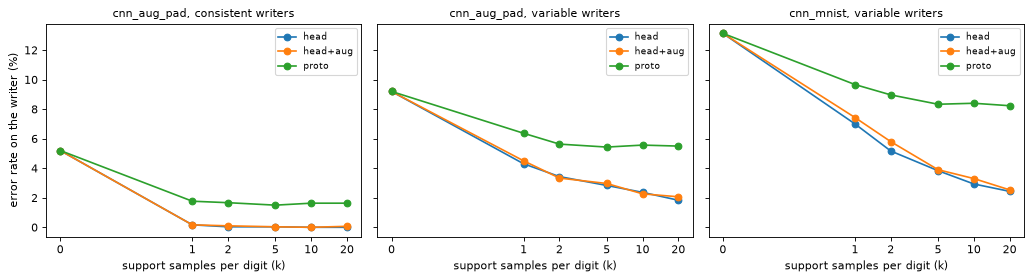

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, (b, wset) in zip(ax, RUNS):
    for method in METHODS:
        a.plot(KS, 100 * (1 - curves[(b, wset, method)].mean(0)), 'o-', label=method)
    a.set_xscale('symlog', linthresh=1); a.set_xticks(KS, KS)
    a.set_title(f'{b}, {wset} writers', fontsize=10); a.set_xlabel('support samples per digit (k)')
    a.legend(fontsize=8)
ax[0].set_ylabel('error rate on the writer (%)')
plt.tight_layout(); plt.show()

### Who benefits? The hardest writers

Average numbers hide that most writers are already read well; personalisation matters most
for the writers the base model struggles with.

In [7]:
acc = curves[('cnn_aug_pad', 'variable', 'head+aug')]
for i in np.argsort(acc[:, 0])[:6]:
    print(f'writer {10 + i:2d}: base {acc[i, 0]:.0%} -> k=5 {acc[i, KS.index(5)]:.0%} -> k=20 {acc[i, -1]:.0%}')
print(f'worst writer: {acc[:, 0].min():.0%} before, {acc[:, KS.index(5)].min():.0%} after 5 samples per digit')

writer 38: base 81% -> k=5 95% -> k=20 99%
writer 30: base 83% -> k=5 97% -> k=20 97%
writer 34: base 83% -> k=5 96% -> k=20 98%
writer 28: base 84% -> k=5 91% -> k=20 98%
writer 32: base 84% -> k=5 97% -> k=20 97%
writer 20: base 87% -> k=5 93% -> k=20 96%
worst writer: 81% before, 90% after 5 samples per digit


### Does it forget? Accuracy on *other* writers after adapting to one

The adapted head would live on one player's device only, but it should not become useless
for a sibling who borrows the tablet.

In [8]:
feat, _, W0 = split_model(bases['cnn_aug_pad'])
x_gen, y_gen = ev.load_test_sets(with_real=False)['pad_tmpl']
f_gen = feat(x_gen)
base_gen = (head_forward(f_gen, W0).numpy().argmax(1) == y_gen).mean()
x_v, y_v, w_v = writers['variable']
after = []
for wid in range(10, 20):
    m = (w_v == wid) & (np.arange(len(w_v)) % 30 < 5)
    W = finetune_head(feat(augmented(x_v[m])), np.tile(y_v[m], 5), W0, **best_hp['head'])
    after.append((head_forward(f_gen, W).numpy().argmax(1) == y_gen).mean())
print(f'general pad_tmpl accuracy: base {base_gen:.2%}, after adapting to one writer (k=5) '
      f'{np.mean(after):.2%} (min {np.min(after):.2%})')

general pad_tmpl accuracy: base 95.03%, after adapting to one writer (k=5) 96.54% (min 93.96%)


### Real samples

With real samples from `collect/` (at least 4 per digit for one writer) the same experiment
runs on real handwriting: half of each digit's samples adapt, the other half test.

In [9]:
real = [s for s in datasets.load_real_samples() if s['writer'] != 'pipeline-check']
if real:
    xr = np.stack([s['img28'] for s in real]); yr = np.array([int(s['label']) for s in real])
    wr = np.array([s['writer'] for s in real])
    for name in np.unique(wr):
        cnt = np.array([((wr == name) & (yr == d)).sum() for d in range(10)])
        if cnt.min() < 4:
            print(name, 'needs at least 4 samples of every digit'); continue
        sup = np.concatenate([np.nonzero((wr == name) & (yr == d))[0][:cnt[d] // 2] for d in range(10)])
        qry = np.concatenate([np.nonzero((wr == name) & (yr == d))[0][cnt[d] // 2:] for d in range(10)])
        f_q = feat(xr[qry])
        base_acc = (head_forward(f_q, W0).numpy().argmax(1) == yr[qry]).mean()
        W = finetune_head(feat(augmented(xr[sup])), np.tile(yr[sup], 5), W0, **best_hp['head'])
        print(f'{name}: {len(sup)} adapt / {len(qry)} test -> base {base_acc:.1%}, adapted '
              f'{(head_forward(f_q, W).numpy().argmax(1) == yr[qry]).mean():.1%}')
else:
    print('No real samples yet.')

No real samples yet.


## Export for an on-device version (TF.js)

On the device the frozen part is a normal TF.js graph model that returns the 64-d pooled
features; the head is 4 small tensors that TF.js can train with `tf.train.adam` (no layers
model and no converter support for training needed). `export/bench.html` times exactly that:
features for 50 samples + the Adam steps chosen above, in WASM.

In [10]:
import json, shutil
from pathlib import Path
from tensorflowjs.converters import tf_saved_model_conversion_v2 as tfjs_conv

_, feat_model, W0 = split_model(bases['cnn_aug_pad'])
sm = datasets.CACHE / 'saved_cnn_features'
feat_model.export(str(sm), verbose=False)
shutil.rmtree('export/cnn_features_tfjs', ignore_errors=True)
tfjs_conv.convert_tf_saved_model(str(sm), 'export/cnn_features_tfjs', signature_def='serving_default',
                                 saved_model_tags='serve')
_ = Path('export/cnn_head.json').write_text(json.dumps({
    'names': ['embedding/kernel', 'embedding/bias', 'classifier/kernel', 'classifier/bias'],
    'shapes': [list(w.shape) for w in W0], 'values': [np.round(w, 6).ravel().tolist() for w in W0],
    'hyperparameters': best_hp['head']}))
print(f"features model {sum(f.stat().st_size for f in Path('export/cnn_features_tfjs').iterdir()) / 1024:.0f} KB, "
      f"head {Path('export/cnn_head.json').stat().st_size / 1024:.0f} KB (JSON)")

features model 409 KB, head 101 KB (JSON)


## 小结

| 基础模型 / 书写者 | k=0 | k=1 | k=5 | k=20 |
|---|---|---|---|---|
| cnn_aug_pad / variable，`head` | 90.8% | 95.7% | **97.2%** | 98.2% |
| cnn_aug_pad / variable，`proto` | 90.8% | 93.6% | 94.6% | 94.5% |
| cnn_mnist / variable，`head` | 86.9% | 93.0% | 96.2% | 97.6% |
| cnn_aug_pad / consistent，`head` | 94.8% | 99.8% | 100% | 100% |

- 冻结卷积层、只微调最后两层全连接（4,810 个参数），**每个数字 5 个样本**就能把"变化较大的书写者"的错误率从 9.2% 降到 2.8%（约 −70%）；
  最难的书写者从 81% 提升到 90–97%。
- "一致型"合成书写者太理想（1 个样本就接近 100%），只能作为上界；真实玩家更接近 variable 设定，最终需要用 `collect/` 的真实样本验证。
- 原型法（不训练）几乎零成本但收益小很多；对支持样本做增强在这里没有额外收益。
- 弱基础模型（只用 MNIST）从个性化中获益更多，但 k=5 后仍略差于强基础模型 —— 先把基础模型做好仍然更重要。
- 适配某个书写者后，对其他书写者的平均准确率不降反升（95.0% → 平均 96.5%），最差的一次下降 1.1 个百分点（94.0%），L2 约束基本防止了遗忘。
- 浏览器端可行：特征提取用 TF.js graph model，头部用 `tf.variable` + `tf.train.adam` 训练；`export/bench.html` 在 WASM 中实测
  50 个样本的特征提取 + 训练只需几百毫秒（见 README）。